# Bangkok Taxi Area Recommender — Consolidated Final Replay Evaluation
### Validation, held-out test, checkpoint analyses, and driving-time sensitivity

**One report notebook.** This notebook reads saved CSV outputs; it does not train models or rerun the replay. The driving-penalty analysis is **validation-only** and is not a new held-out test result.


## Reader's guide — what this evaluation actually tells us

**The main question:** When an empty taxi needs its next passenger, which recommendation strategy is estimated to get it there sooner? This notebook compares **Model A, Model B, Heatmap, Random, and Stay**. It **does not train the models** or prove what would happen in a real taxi experiment. It reads results saved by an offline replay of historical taxi situations.

**Imagine one example:** A taxi has just dropped off a passenger. Model B says “drive to Area X”; Heatmap says “drive to Area Y”; Stay says “remain here.” We cannot send that same historical taxi to all three places. Instead, the replay looks for *other* similar taxi situations in the historical data to estimate how long each recommendation might take. The estimated score includes driving time and waiting time. **Lower is better.**

### How to read the notebook, section by section

| Section | What you are looking at | Question it answers |
|---|---|---|
| **1. Protocol** | Train/validation/test dates, 100 sampled decisions per day, evaluation rules | *Was the evaluation set up fairly?* |
| **2. Strategy summary** | Five strategies' average estimated scores and coverage | *What does each strategy look like on the cases with enough evidence?* **Do not rank strategies by these averages alone**: their covered cases differ. |
| **3. Versus Heatmap** | Fair, same-decision comparisons against a simple demand-map strategy | *Does a strategy beat the basic Heatmap?* |
| **4. Model B versus Stay** | Direct same-decision comparison | *Is following Model B better than not relocating?* This is the most important head-to-head result. |
| **5. Empty-time checkpoints** | Results for taxis empty for 0, 5, 15, 30, or 45 minutes | *Does the answer depend on how long the taxi has been empty?* |
| **6. Coverage by checkpoint** | Percent of decisions for which historical evidence was sufficient | *Where are our conclusions based on fewer cases?* |
| **7. Conclusions and limits** | Main findings and cautions | *What can we responsibly claim?* |
| **8–9. Reproducibility** | Input files and saved run settings | *Can teammates trace where the results came from?* |
| **10. Driving-time sensitivity** | A validation-only experiment counting 100%, 75%, or 50% of direct driving cost | *Would our conclusion change if driving were penalized less?* |
| **11. Integrated findings** | Formal summary for reports | *How do all the results fit together?* |

### A small glossary — statistical terms without the jargon

| Term in the notebook | Plain meaning |
|---|---|
| **Strategy / policy** | A rule or model that tells the taxi where to go next. **Stay** is also a strategy. |
| **Offline replay** | Testing recommendations using past taxi records instead of sending real drivers out. |
| **Decision / checkpoint** | One moment when the taxi could choose what to do; checkpoints are after 0, 5, 15, 30, or 45 minutes empty. |
| **Score (minutes)** | Estimated driving-plus-waiting time until a pickup, under the replay's assumptions. **Smaller is better.** |
| **Coverage / evaluability** | The percentage of decisions for which enough comparable historical trips existed to estimate a score. Missing coverage does **not** mean failure. |
| **Paired comparison** | Compare two strategies **on exactly the same decisions** so the comparison is fair. |
| **Mean / average difference** | Roughly how many minutes one strategy scores better or worse, on average, in those paired cases. |
| **95% confidence interval (CI)** | A range expressing uncertainty around the estimated average. A narrower range means more precision; it is **not** a promise about any individual taxi. |
| **Interval includes zero** | The data are compatible with little or no average difference under that scenario; we cannot confidently declare a winner from this interval. |
| **Day-level bootstrap** | Recalculate the result many times after resampling whole days, to estimate uncertainty while accounting for decisions from the same day being related. |
| **Validation vs held-out test** | Validation is used to explore and check ideas. The protected test period is used for the final original evaluation. The new sensitivity experiment is **validation-only**. |
| **Survival curve / Kaplan–Meier** | A way to estimate the chance a taxi is still waiting at each minute, even when some trips end before their eventual pickup is observed. |
| **Sensitivity analysis** | Change an assumption and see whether the conclusion stays similar. It does **not** prove the alternative assumption is true. |

### Read these results correctly

**Finding A — Model B improves over Heatmap.** In the held-out test, on **1,427 decisions where both could be evaluated**, Model B's estimated score was **4.54 minutes lower** than Heatmap's (95% CI: **4.11 to 4.99**). So the machine-learning recommendation adds value relative to the simple demand-map baseline in these matched cases.

**Finding B — Stay still beats Model B under the original scoring rule.** On a **different matched set of 1,664 held-out test decisions**, Model B's estimated score was **2.00 minutes higher** than Stay's (95% CI: **1.74 to 2.23**). In other words, a promising destination may not be worth the time spent driving to it. **Do not subtract or combine Findings A and B:** they use different paired sets.

**Finding C — we cannot evaluate every recommendation.** On the held-out test, enough historical evidence existed for roughly **35% of Model B decisions** and **44% of Stay decisions**. This is why we rely on paired comparisons and avoid saying the results apply to every taxi situation.

**Finding D — driving-time assumptions matter.** In the **validation-only** penalty sensitivity check (1,725 matched decisions across 55 days), Model B's disadvantage against Stay decreased from **1.87 minutes** when all driving time counted, to **1.07 minutes** at 75%, and **0.27 minutes** at 50%. At 50%, the 95% CI was **−0.02 to 0.55**, which includes zero. This means Stay was **not clearly better under that hypothetical penalty**, not that Model B was proven better or that taxis really pick up passengers en route.

**Bottom line:** *Model B finds better destinations than Heatmap, but relocating is not necessarily better than staying once travel time is counted.* These are careful historical estimates, **not a live field experiment**.


## 1. Protocol and evaluation design

| Component | Frozen design |
|---|---|
| Training | Jan 29–Sep 15, 2025 (Aug 29 excluded) |
| Validation | Sep 16–Nov 9, 2025; **55 days × 100 = 5,500 decisions** |
| Held-out test | Nov 10–Dec 31, 2025; **52 days × 100 = 5,200 decisions** |
| Sampling | Deterministic, **checkpoint-stratified** by day; seed 42 |
| Checkpoints | 0, 5, 15, 30, 45 minutes into an empty episode |
| Policies | Model B, Model A, Heatmap, Random, Stay |
| Outcome | Retrospective estimated waiting-time score; lower is better |
| Uncertainty | Paired **day-bootstrap**, 2,000 resamples for Heatmap comparisons |
| Historical peers | Same split, other vehicles/episodes, at least 5 peers |

**Important:** Equal checkpoint allocation does not represent the natural distribution of empty-trip checkpoints. These results describe the sampled, checkpoint-balanced decisions, not population-weighted performance. Historical peer comparisons are **not causal estimates**.

In [10]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display

# Works when opened from the ML-Project root, or from the evaluation_report folder.
ROOT = Path.cwd()
CANDIDATES = [ROOT / 'pipeline_output' / 'replay' / 'evaluation_report', ROOT, ROOT / 'evaluation_report']
FILES = ['validation_test_policy_summary.csv','validation_test_heatmap_bootstrap.csv',
         'validation_test_model_b_vs_stay.csv','validation_checkpoint_paired_b_vs_stay.csv',
         'test_checkpoint_paired_b_vs_stay.csv','validation_checkpoint_coverage.csv',
         'test_checkpoint_coverage.csv']
DATA_DIR = next((p for p in CANDIDATES if all((p / f).is_file() for f in FILES)), None)
if DATA_DIR is None:
    raise FileNotFoundError('Could not find seven evaluation_report CSV files. Run from ML-Project root, or place the CSVs beside the notebook.')
data = {name.replace('.csv',''): pd.read_csv(DATA_DIR / name) for name in FILES}
print('Reading exported results from:', DATA_DIR.resolve())
print('Loaded', len(data), 'CSV files')

Reading exported results from: C:\AIT\ML\Group Project\ML-Project\pipeline_output\replay\evaluation_report
Loaded 7 CSV files


## 2. Strategy performance and evaluability

The following means are **descriptive only**: each policy's score is averaged over its *own* evaluable subset. Policies have different coverage, so direct comparisons should use the paired tables in Sections 3 and 4.


VALIDATION


,Strategy,Decisions,Evaluable,Coverage (%),Mean score (min)
0,Heatmap,5500,2277,41.4,31.15
1,Model A,5500,2300,41.8,31.18
2,Model B,5500,1890,34.4,24.75
3,Random,5500,1389,25.3,31.85
4,Stay,5500,2456,44.7,23.45



TEST


,Strategy,Decisions,Evaluable,Coverage (%),Mean score (min)
0,Heatmap,5200,2180,41.9,31.93
1,Model A,5200,2207,42.4,31.96
2,Model B,5200,1818,35.0,25.99
3,Random,5200,1341,25.8,32.31
4,Stay,5200,2306,44.3,24.60


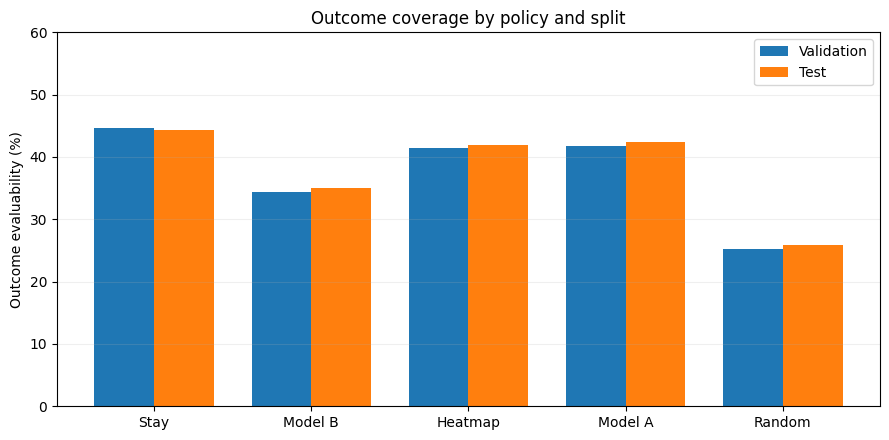

In [11]:
s = data['validation_test_policy_summary'].copy()
s['Strategy'] = s['strategy'].map({'model_a':'Model A','model_b':'Model B','heatmap':'Heatmap','random':'Random','stay':'Stay'})
s['Coverage (%)'] = (100*s['coverage_rate']).round(1)
s['Mean score (min)'] = s['mean_score_min'].round(2)
s['Evaluable'] = s['n_evaluable'].astype(int)
for split in ['validation','test']:
    print('\n'+split.upper())
    display(s.loc[s['split']==split,['Strategy','n_decisions','Evaluable','Coverage (%)','Mean score (min)']].rename(columns={'n_decisions':'Decisions'}).reset_index(drop=True))
fig, ax = plt.subplots(figsize=(9,4.5))
order=['Stay','Model B','Heatmap','Model A','Random']
for i,split in enumerate(['validation','test']):
    z=s[s['split']==split].set_index('Strategy').reindex(order)
    ax.bar(np.arange(len(order))+(i-.5)*.38,z['Coverage (%)'],width=.38,label=split.title())
ax.set_xticks(np.arange(len(order)),order)
ax.set_ylabel('Outcome evaluability (%)'); ax.set_ylim(0,60)
ax.set_title('Outcome coverage by policy and split'); ax.legend(); ax.grid(axis='y',alpha=.2)
plt.tight_layout(); plt.show()

**Interpretation.** Test outcome coverage is approximately **44.3% for Stay, 35.0% for Model B, 41.9% for Heatmap, 42.4% for Model A, and 25.8% for Random**. Model B has an estimated mean score of **25.99 min** and Stay **24.60 min** on their respective evaluable subsets. **Do not subtract these unpaired means**: differences in which decisions are evaluable can bias that comparison. Missing outcomes are a central limitation.

## 3. Paired comparisons against Heatmap

Each comparison uses only decisions where **both** the strategy and Heatmap have evaluable outcomes. **Positive improvement** means the strategy's estimated score is *lower* than Heatmap's. Error bars are 95% paired day-bootstrap confidence intervals.

,Split,Strategy,Paired n,Improvement (min),95% lower,95% upper
0,validation,Model A,2124,-0.09,-0.25,0.07
1,validation,Model B,1494,4.94,4.45,5.41
2,validation,Random,1176,-0.59,-1.11,-0.08
3,validation,Stay,1789,7.25,6.85,7.69
4,test,Model A,2016,0.07,-0.12,0.26
5,test,Model B,1427,4.54,4.11,4.99
6,test,Random,1102,-0.63,-1.12,-0.10
7,test,Stay,1695,6.93,6.56,7.30


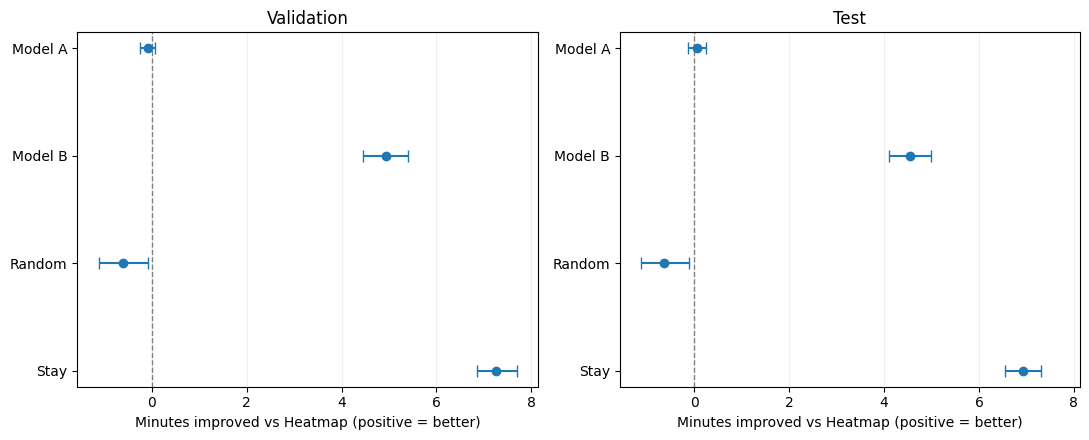

In [12]:
b=data['validation_test_heatmap_bootstrap'].copy()
b['Strategy']=b['strategy'].map({'model_a':'Model A','model_b':'Model B','random':'Random','stay':'Stay'})
display(b[['split','Strategy','n_paired_decisions','mean_improvement_min','ci_lower_min','ci_upper_min']].rename(columns={'split':'Split','n_paired_decisions':'Paired n','mean_improvement_min':'Improvement (min)','ci_lower_min':'95% lower','ci_upper_min':'95% upper'}).round(2).reset_index(drop=True))
fig,axs=plt.subplots(1,2,figsize=(11,4.5),sharex=True)
order=['Model A','Model B','Random','Stay']
for ax,split in zip(axs,['validation','test']):
    t=b[b['split']==split].set_index('Strategy').reindex(order)
    y=np.arange(len(order))
    x=t['mean_improvement_min'].to_numpy()
    err=np.vstack((x-t['ci_lower_min'].to_numpy(),t['ci_upper_min'].to_numpy()-x))
    ax.errorbar(x,y,xerr=err,fmt='o',capsize=4)
    ax.axvline(0,color='gray',linestyle='--',linewidth=1)
    ax.set_yticks(y,order); ax.invert_yaxis(); ax.set_title(split.title()); ax.grid(axis='x',alpha=.2)
    ax.set_xlabel('Minutes improved vs Heatmap (positive = better)')
plt.tight_layout(); plt.show()

**Interpretation.** Model B beats Heatmap in **validation (+4.94 min; 95% CI 4.45–5.41; n=1,494)** and **test (+4.54 min; 95% CI 4.11–4.99; n=1,427)**. Stay shows a larger improvement against Heatmap (**+7.25 min validation; +6.93 min test**), but those two strategy-versus-Heatmap estimates use **different paired subsets**, so the difference between +6.93 and +4.54 is **not** the direct Stay-versus-Model B effect. Model A is close to Heatmap with intervals crossing zero; Random is modestly worse.

## 4. Direct Model B versus Stay — primary head-to-head result

This table is the **correct** direct comparison: it uses only decisions where Model B **and** Stay are both evaluable. The contrast is **Model B minus Stay**, so **positive means Stay is better**. The reported confidence intervals are taken from the exported paired analysis.

,Split,Paired decisions,Days,Model B − Stay (min),95% lower,95% upper
0,validation,1725,55,1.865,1.567,2.136
1,test,1664,52,1.998,1.744,2.226


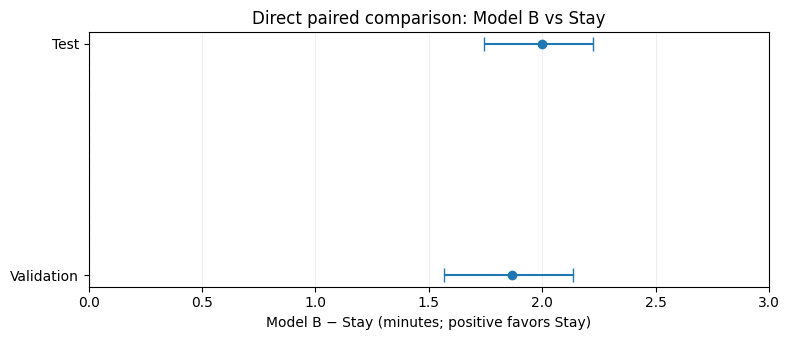

In [13]:
h=data['validation_test_model_b_vs_stay'].copy()
h['Model B − Stay (min)']=h['model_b_minus_stay_min']
display(h[['split','n_paired','n_days','Model B − Stay (min)','ci_lower','ci_upper']].rename(columns={'split':'Split','n_paired':'Paired decisions','n_days':'Days','ci_lower':'95% lower','ci_upper':'95% upper'}).round(3).reset_index(drop=True))
fig,ax=plt.subplots(figsize=(8,3.5))
y=np.arange(len(h)); x=h['model_b_minus_stay_min'].to_numpy()
ax.errorbar(x,y,xerr=np.vstack((x-h['ci_lower'],h['ci_upper']-x)),fmt='o',capsize=5)
ax.set_yticks(y,h['split'].str.title()); ax.set_xlabel('Model B − Stay (minutes; positive favors Stay)')
ax.axvline(0,color='gray',linestyle='--'); ax.set_xlim(0,3); ax.grid(axis='x',alpha=.2)
ax.set_title('Direct paired comparison: Model B vs Stay'); plt.tight_layout(); plt.show()

**Interpretation.** On the directly matched subset, Model B has an estimated score **1.87 min higher than Stay** in validation (**n=1,725; 95% CI 1.57–2.14**) and **2.00 min higher** in test (**n=1,664; 95% CI 1.74–2.23**). Both intervals exclude zero, and the direction is consistent across splits. This is evidence that **Stay performs better on the evaluable paired subset**, **not** that staying would causally reduce waiting for every taxi.

## 5. Sensitivity by empty-trip checkpoint

The next chart displays the direct paired **Model B minus Stay** difference at each checkpoint. The checkpoint CSVs contain descriptive means and sample counts, **not checkpoint-specific bootstrap intervals**; no subgroup statistical significance is claimed here.

,Checkpoint (min),Model B − Stay (min),Paired n,Split
0,0,2.873,479,validation
1,5,1.781,493,validation
2,15,1.288,394,validation
3,30,1.493,217,validation
4,45,0.927,142,validation
5,0,2.712,409,test
6,5,2.068,473,test
7,15,1.755,411,test
8,30,1.491,199,test
9,45,1.272,172,test


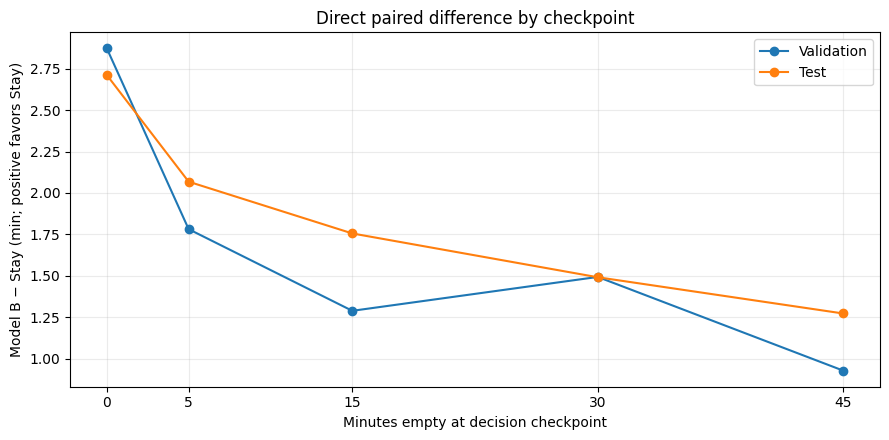

In [14]:
parts=[]
for split in ['validation','test']:
    z=data[f'{split}_checkpoint_paired_b_vs_stay'].copy()
    z['split']=split
    parts.append(z)
cp=pd.concat(parts,ignore_index=True)
display(cp.rename(columns={'checkpoint_min':'Checkpoint (min)','mean':'Model B − Stay (min)','count':'Paired n','split':'Split'}).round(3).reset_index(drop=True))
fig,ax=plt.subplots(figsize=(9,4.5))
for split in ['validation','test']:
    z=cp[cp['split']==split].sort_values('checkpoint_min')
    ax.plot(z['checkpoint_min'],z['mean'],marker='o',label=split.title())
ax.set_xticks([0,5,15,30,45]); ax.set_xlabel('Minutes empty at decision checkpoint')
ax.set_ylabel('Model B − Stay (min; positive favors Stay)'); ax.set_title('Direct paired difference by checkpoint')
ax.grid(alpha=.25); ax.legend(); plt.tight_layout(); plt.show()

**Interpretation.** Stay has a lower estimated score at **all five checkpoints** in both validation and test. The gap is largest at **0 min** (validation **2.87**, test **2.71** min) and generally smaller at later checkpoints (45 min: validation **0.93**, test **1.27** min). These are exploratory subgroup means, with fewer paired observations later in the trip. A changing sample of evaluable decisions may explain part of the pattern.

## 6. Checkpoint outcome coverage — why missingness matters

Coverage is the share of sampled decisions with sufficient historical comparison data to estimate the outcome. The CSVs report counts by strategy and checkpoint.

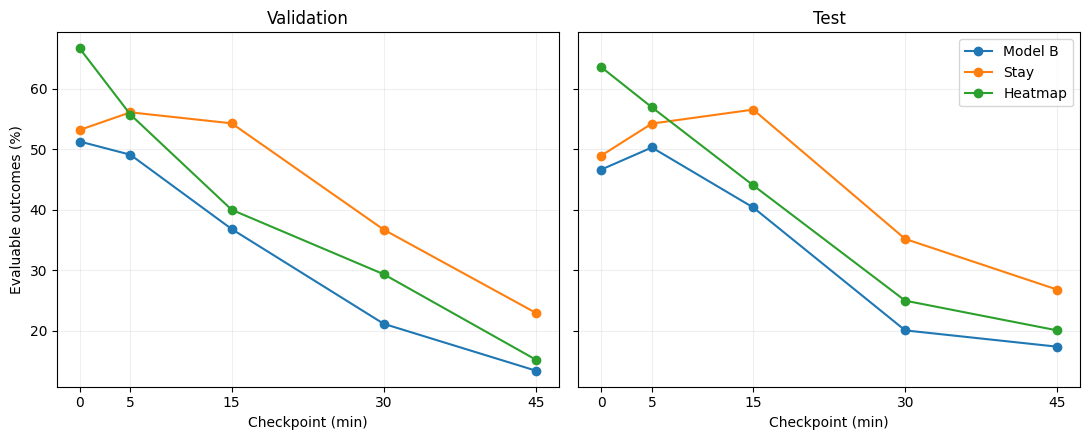

,Split,Checkpoint,Strategy,Evaluable,Decisions,Coverage (%)
0,validation,0,heatmap,733,1100,66.6
1,validation,0,model_b,564,1100,51.3
2,validation,0,stay,585,1100,53.2
3,validation,5,heatmap,613,1100,55.7
4,validation,5,model_b,540,1100,49.1
5,validation,5,stay,617,1100,56.1
6,validation,15,heatmap,440,1100,40.0
7,validation,15,model_b,405,1100,36.8
8,validation,15,stay,597,1100,54.3
9,validation,30,heatmap,323,1100,29.4


In [15]:
coverage=[]
for split in ['validation','test']:
    z=data[f'{split}_checkpoint_coverage'].copy();z['split']=split
    coverage.append(z)
cov=pd.concat(coverage,ignore_index=True)
fig,axs=plt.subplots(1,2,figsize=(11,4.5),sharey=True)
for ax,split in zip(axs,['validation','test']):
    for strategy in ['model_b','stay','heatmap']:
        z=cov[(cov['split']==split)&(cov['strategy']==strategy)].sort_values('checkpoint_min')
        ax.plot(z['checkpoint_min'],100*z['mean'],marker='o',label=strategy.replace('_',' ').title())
    ax.set_xticks([0,5,15,30,45]); ax.set_xlabel('Checkpoint (min)');ax.set_title(split.title());ax.grid(alpha=.2)
axs[0].set_ylabel('Evaluable outcomes (%)');axs[1].legend()
plt.tight_layout();plt.show()
focus=cov[cov['strategy'].isin(['model_b','stay','heatmap'])].copy()
focus['Coverage (%)']=(100*focus['mean']).round(1)
display(focus[['split','checkpoint_min','strategy','sum','count','Coverage (%)']].rename(columns={'split':'Split','checkpoint_min':'Checkpoint','strategy':'Strategy','sum':'Evaluable','count':'Decisions'}).reset_index(drop=True))

**Interpretation.** Model B test coverage drops from **46.6% at 0 min** to **17.4% at 45 min**. Late-checkpoint comparisons therefore depend on a smaller, potentially nonrepresentative subset. The retrospective matching rule requires independent historical peers; missing matches are **not equivalent to failed predictions**. Coverage should be reported alongside every performance claim.

## 7. Overall conclusion and limitations

**Main result.** On the sampled held-out test period, **Model B improves on Heatmap by 4.54 minutes** (paired 95% CI **4.11–4.99**) but is **2.00 minutes worse than Stay** on directly paired evaluable decisions (95% CI **1.74–2.23**). Validation shows the same direction. Thus, **a better model-based relocation strategy than Heatmap does not necessarily outperform a no-relocation policy**.

**What this does not establish:**

- **No causal treatment effect:** outcomes use retrospective same-split historical peers rather than observing the counterfactual pickup for the same taxi.
- **Incomplete and selective outcome coverage:** Model B has an evaluable outcome for roughly **35%** of test decisions, with worse coverage later in empty episodes.
- **Checkpoint-balanced sample:** 100 decisions per day were stratified across five checkpoints; the aggregate is not automatically representative of all empty taxi episodes.
- **Approximate driving assumptions:** reachability and travel time use a fixed speed approximation, not observed real-time traffic.
- **Subgroup uncertainty:** checkpoint-specific tables here contain descriptive means, not bootstrap confidence intervals.
- **No post-test tuning:** test data are used only to assess the frozen protocol.

**Practical recommendation:** present Model B as an improvement over Heatmap **within the retrospectively evaluable subset**, and present Stay as a strong baseline that the recommender has **not** surpassed in this evaluation. Do not claim proven operational savings without prospective or randomized testing.

## 8. Data provenance and reproducibility

The notebook reads exactly these seven files from `pipeline_output/replay/evaluation_report/`:

- `validation_test_policy_summary.csv`
- `validation_test_heatmap_bootstrap.csv`
- `validation_test_model_b_vs_stay.csv`
- `validation_checkpoint_paired_b_vs_stay.csv`
- `test_checkpoint_paired_b_vs_stay.csv`
- `validation_checkpoint_coverage.csv`
- `test_checkpoint_coverage.csv`

The original `validation_sampled/` and `test_sampled/` replay outputs remain the authoritative sources for these exports. **The plots and tables are already saved as outputs inside this notebook**, and running all cells refreshes them from the CSVs. No replay or training is performed.

## 9. Reproducibility and frozen-protocol checks

The original sampled validation and test runs remain authoritative. The following checks compare their saved metadata and confirm that the model selection and core replay parameters match. The sensitivity run uses its **own** validation output directory, and its altered scores do not replace the original outcome estimates.


In [16]:
import json
REPLAY_ROOT = DATA_DIR.parent
RUN_FOLDERS = {'validation': REPLAY_ROOT/'validation_sampled', 'test': REPLAY_ROOT/'test_sampled'}
metadata = {}
for split, folder in RUN_FOLDERS.items():
    path = folder/'run_metadata.json'
    if path.exists():
        metadata[split] = json.loads(path.read_text())
        m = metadata[split]
        print(f"{split}: {m.get('decisions')} decisions; {len(m.get('days', []))} days; sample/day={m.get('sample_per_day')}; seed={m.get('seed')}")
    else:
        print(f'{split}: metadata not found at {path}; protocol check skipped')
if len(metadata)==2:
    settings = ['speed_kmh','empty_tolerance_min','min_episodes','training_coverage_min','sample_method']
    mismatches = [k for k in settings if metadata['validation'].get(k)!=metadata['test'].get(k)]
    for model in ['model_a','model_b']:
        if metadata['validation'].get('model_selection',{}).get(model)!=metadata['test'].get('model_selection',{}).get(model):
            mismatches.append(model)
    assert not mismatches, f'Validation/test protocol mismatches: {mismatches}'
    assert all(m.get('sample_per_day')==100 and m.get('seed')==42 for m in metadata.values())
    print('Frozen validation/test settings match.')


validation: 5500 decisions; 55 days; sample/day=100; seed=42
test: 5200 decisions; 52 days; sample/day=100; seed=42
Frozen validation/test settings match.



## 10. Driving-time penalty sensitivity — additional validation experiment

The original score is $D + \sum_{t=0}^{60-\lceil D\rceil-1} S(t)$, where $D$ is estimated driving time and $S(t)$ is the historical peer-based waiting survival probability.

For this **fixed-recommendation penalty-only** check, the historical peers, waiting contribution, 60-minute horizon, and recommended areas remain fixed. Only the direct penalty is adjusted:

$$
\text{Adjusted score}_{\alpha} = \text{Original score} - (1-\alpha)D,
\qquad \alpha \in \{1, 0.75, 0.5\}
$$

The table compares **Model B minus Stay** on the **same 1,725 jointly evaluable decisions**, across **55 validation days**, with 95% confidence intervals from day-level bootstrap resampling.

**Positive values favor Stay.**

This does not model pickups during relocation, changed arrival times, changed peer matching, or reranked recommendations.


Loaded actual sensitivity results: c:\AIT\ML\Group Project\ML-Project\pipeline_output\replay\driving_sensitivity_validation\driving_time_sensitivity.csv


,drive_penalty_fraction,n_paired_decisions,n_days,model_b_minus_stay_min,ci_95_low,ci_95_high
0,1.00,1725,55,1.865,1.570,2.137
1,0.75,1725,55,1.067,0.795,1.323
2,0.50,1725,55,0.268,-0.018,0.550


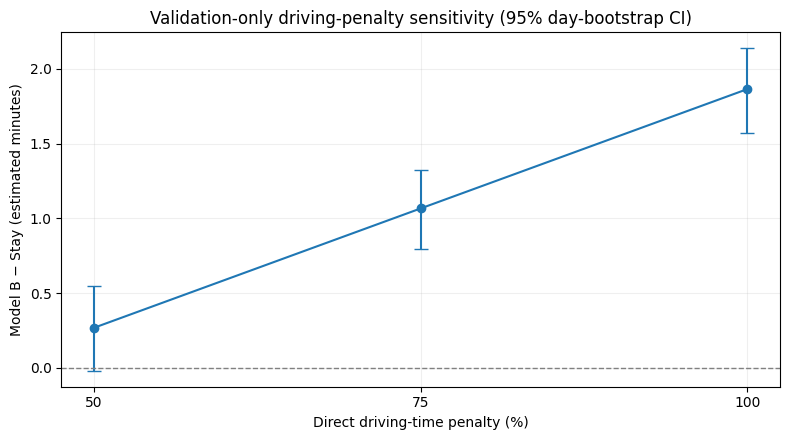

In [17]:
SENSITIVITY_FILE = REPLAY_ROOT/'driving_sensitivity_validation'/'driving_time_sensitivity.csv'
if SENSITIVITY_FILE.is_file():
    sensitivity = pd.read_csv(SENSITIVITY_FILE)
    print('Loaded actual sensitivity results:', SENSITIVITY_FILE)
else:
    # Recorded results supplied from the completed validation run. Replace automatically
    # with the saved CSV whenever the notebook runs in the original project.
    sensitivity = pd.DataFrame([
        {'drive_penalty_fraction':1.00,'n_paired_decisions':1725,'n_days':55,'model_b_minus_stay_min':1.865030,'ci_95_low':1.570222,'ci_95_high':2.137008},
        {'drive_penalty_fraction':0.75,'n_paired_decisions':1725,'n_days':55,'model_b_minus_stay_min':1.066621,'ci_95_low':0.795494,'ci_95_high':1.323428},
        {'drive_penalty_fraction':0.50,'n_paired_decisions':1725,'n_days':55,'model_b_minus_stay_min':0.268211,'ci_95_low':-0.018207,'ci_95_high':0.549838},
    ])
    print('Sensitivity CSV not found; displaying the completed run results supplied in chat.')
assert {'drive_penalty_fraction','model_b_minus_stay_min','ci_95_low','ci_95_high'}.issubset(sensitivity.columns)
display(sensitivity.round(3))
fig, ax = plt.subplots(figsize=(8,4.5))
z = sensitivity.sort_values('drive_penalty_fraction')
x = z['drive_penalty_fraction']*100
y = z['model_b_minus_stay_min']
ax.errorbar(x, y, yerr=[y-z['ci_95_low'],z['ci_95_high']-y], fmt='o-', capsize=5)
ax.axhline(0, color='gray', linestyle='--', linewidth=1)
ax.set_xticks([50,75,100]); ax.set_xlabel('Direct driving-time penalty (%)')
ax.set_ylabel('Model B − Stay (estimated minutes)')
ax.set_title('Validation-only driving-penalty sensitivity (95% day-bootstrap CI)')
ax.grid(alpha=.2)
plt.tight_layout(); plt.show()


**Interpretation.** With the original 100% driving penalty, Model B scores **1.87 minutes worse** than Stay (95% CI **1.57–2.14**). At 75%, the disadvantage falls to **1.07 minutes** (95% CI **0.80–1.32**). At 50%, the difference shrinks to **0.27 minutes** (95% CI **−0.02–0.55**); because the interval crosses zero, the paired comparison does not clearly favor either policy under that hypothetical penalty.

This is an important qualification to the main conclusion: **the apparent advantage of staying is sensitive to how relocation driving is penalized**. It does not establish that Model B would actually perform better if pickups during travel were modeled. The validation sensitivity does not overturn the frozen held-out test result under the original scoring protocol.


## 11. Final integrated findings and limitations — report-ready narrative

**Evaluation design.** The frozen strategies (Model A, Model B, Heatmap, Random, and Stay) were evaluated using a retrospective offline replay. Decisions were sampled deterministically at five empty-taxi checkpoints (0, 5, 15, 30, and 45 minutes), with 100 decisions per day. The original validation split contains **5,500 decisions across 55 days** and the held-out test split contains **5,200 decisions across 52 days**. For each recommended area, the replay used other independent comparable historical taxi episodes and Kaplan–Meier survival curves to estimate driving-plus-waiting time over a 60-minute horizon. These are estimated counterfactual-style comparisons, **not observed outcomes from actually redirecting taxis**.

**Baseline comparisons.** Model B improves on the Heatmap baseline on jointly evaluable decisions in both validation (**4.94 minutes; 95% CI 4.45–5.41; n=1,494**) and held-out test (**4.54 minutes; 95% CI 4.11–4.99; n=1,427**). These paired results indicate a meaningful improvement over the spatial-demand baseline under the frozen evaluation protocol.

**Stay comparison.** The more demanding head-to-head comparison does not show Model B as the best policy. On the original validation matched subset, Model B has an estimated score **1.87 minutes higher** than Stay. On the held-out test matched subset, Model B is approximately **2.00 minutes worse** (95% CI **1.74–2.23**; n=1,664). A positive Model B-minus-Stay difference means Stay is better. Thus, improving over Heatmap is **not equivalent to improving over doing nothing**.

**Checkpoint robustness.** In the original evaluation, Stay has a lower estimated score than Model B at all five empty-taxi checkpoints on both splits. This suggests the main Stay advantage is not solely due to a single checkpoint group. However, historical outcome coverage falls at later checkpoints; for Model B, test coverage declines from approximately **46.6% at 0 minutes** to **17.4% at 45 minutes**. Late-checkpoint estimates therefore apply to a smaller, more selective set of evaluable decisions.

**Missingness and comparability.** Test outcome coverage is approximately **35.0% for Model B** and **44.3% for Stay**. Because each policy's mean score is computed over its own evaluable subset, **unpaired policy averages should not be interpreted as direct policy rankings**. The paired analyses are the appropriate basis for the comparisons reported here. Neither paired analysis fully eliminates selection bias from limited historical coverage.

**New driving-time sensitivity.** The separate validation-only penalty check uses **1,725 jointly evaluable decisions over 55 days**. Model B-minus-Stay decreases from **+1.87 minutes** (95% CI **1.57–2.14**) at a 100% driving penalty, to **+1.07** (95% CI **0.80–1.32**) at 75%, and **+0.27** (95% CI **−0.02–0.55**) at 50%. The 50% interval includes zero. The advantage of Stay therefore depends substantially on the assumed direct cost of relocation driving. This analysis fixes the recommendations, comparison peers, and original waiting contribution; it **does not** simulate en-route pickups or recompute candidate rankings.

**Overall conclusion.** Model B is stronger than Heatmap, but the frozen held-out evaluation favors Stay under the original driving-plus-waiting objective. The validation-only driving-penalty sensitivity shows that this conclusion becomes much less clear if relocation driving is assigned a lower direct penalty. Future work should test more realistic travel and en-route pickup behavior, better peer coverage, and prospective evaluation before making operational claims.

**Reproducibility and scope.** This notebook summarizes saved original validation/test exports plus the separate sensitivity CSV; it does not rerun models or replace the official test. All 95% intervals are day-level bootstrap intervals on evaluable paired decisions. The sampled evaluation is checkpoint-balanced rather than proportional to all real-world taxi decisions, so aggregate results should not be generalized without considering the sampling design.
